In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math


n_cells = 100

t_final = 1.0e-4
# t_final = 1.0e-5

dt_kd = 1.0e-5
dt_fluid = dt_kd/4

x = np.linspace(0, 1, n_cells+1)
x_center = 0.5 * (x[:-1] + x[1:])
h = x[1] - x[0]

x0 = 0.47

x_split = 0.5


ion_density = np.zeros(n_cells)
ion_density[x_center <= x_split] = 1.0e20
ion_density[x_center >= x_split] = 1.0e20

ion_velocity = np.zeros(n_cells)

ion_temperature = np.zeros(n_cells)
ion_temperature[:] = 1.0

def get_index(x):
    return int(x * n_cells)

def get_BGK_stddev(T):
    return np.sqrt(T * 1.602176634e-19 / 1.67e-27)

def get_collision_rate(T, dens):
    return 3.2e-15 * np.sqrt(T/0.026) * dens

In [ ]:
## Calculate reference solution using eigrene

import eigrene
import json

config = {}

config["mesh"] = {
    "type": "voxel",
    "Lx": 1,
    "Ly": 1,
    "Lz": 1,
    "nx": n_cells,
    "ny": 1,
    "nz": 1,
}

config["background"] = {
    "plasma_dens": ion_density.tolist(),
    "plasma_temp": ion_temperature.tolist(),
    "plasma_vel_x": ion_velocity.tolist(),
    "plasma_vel_y": np.zeros(n_cells, dtype=np.float64).tolist(),
    "plasma_vel_z": np.zeros(n_cells, dtype=np.float64).tolist(),
}

x0_index = get_index(x0)
bgk_stddev = get_BGK_stddev(ion_temperature[x0_index])
x0_velocity = ion_velocity[x0_index]
config["sources"] = [
    {
        "type": "point",
        "n_particles": 100000,
        "intensity": 1.0,
        "pos": [x0, 0.5, 0.5],
        "vel_mean": [x0_velocity, 0, 0],
        "vel_stddev": bgk_stddev,
    },
]

config["boundary_conditions"] = [
    "reflective",
    "reflective",
    "reflective",
    "reflective"
]

config["t_final"] = t_final
config["max_steps"] = 10000000
config["seed"] = 0


inputstring = json.dumps(config)

outputstring = eigrene.simulate(inputstring)

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

density_mc = np.array(output["density"])

{'grid_building_time': 3.572e-06, 'num_collisions': 19848051, 'num_crossings': 7848931, 'total_time': 0.836030572, 'trace_time': 0.836027}


In [ ]:
## for each cell, calculate the 

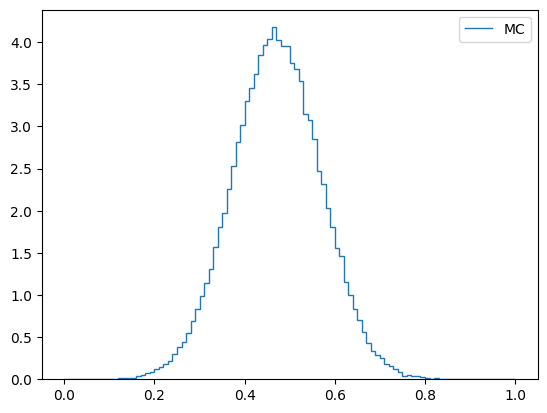

In [9]:
# plt.stairs(ion_density, x, label='BGK')
plt.stairs(density_mc, x, label='MC')
# plt.stairs(density_analytical, x, label='Analytical')
# vertical line at the split
# plt.axvline(x_split, color='r', linestyle='--')
plt.legend()
plt.show()